<a href="https://colab.research.google.com/github/elisabethandriivna/Portfolio/blob/main/Lab3_Kaprelova.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

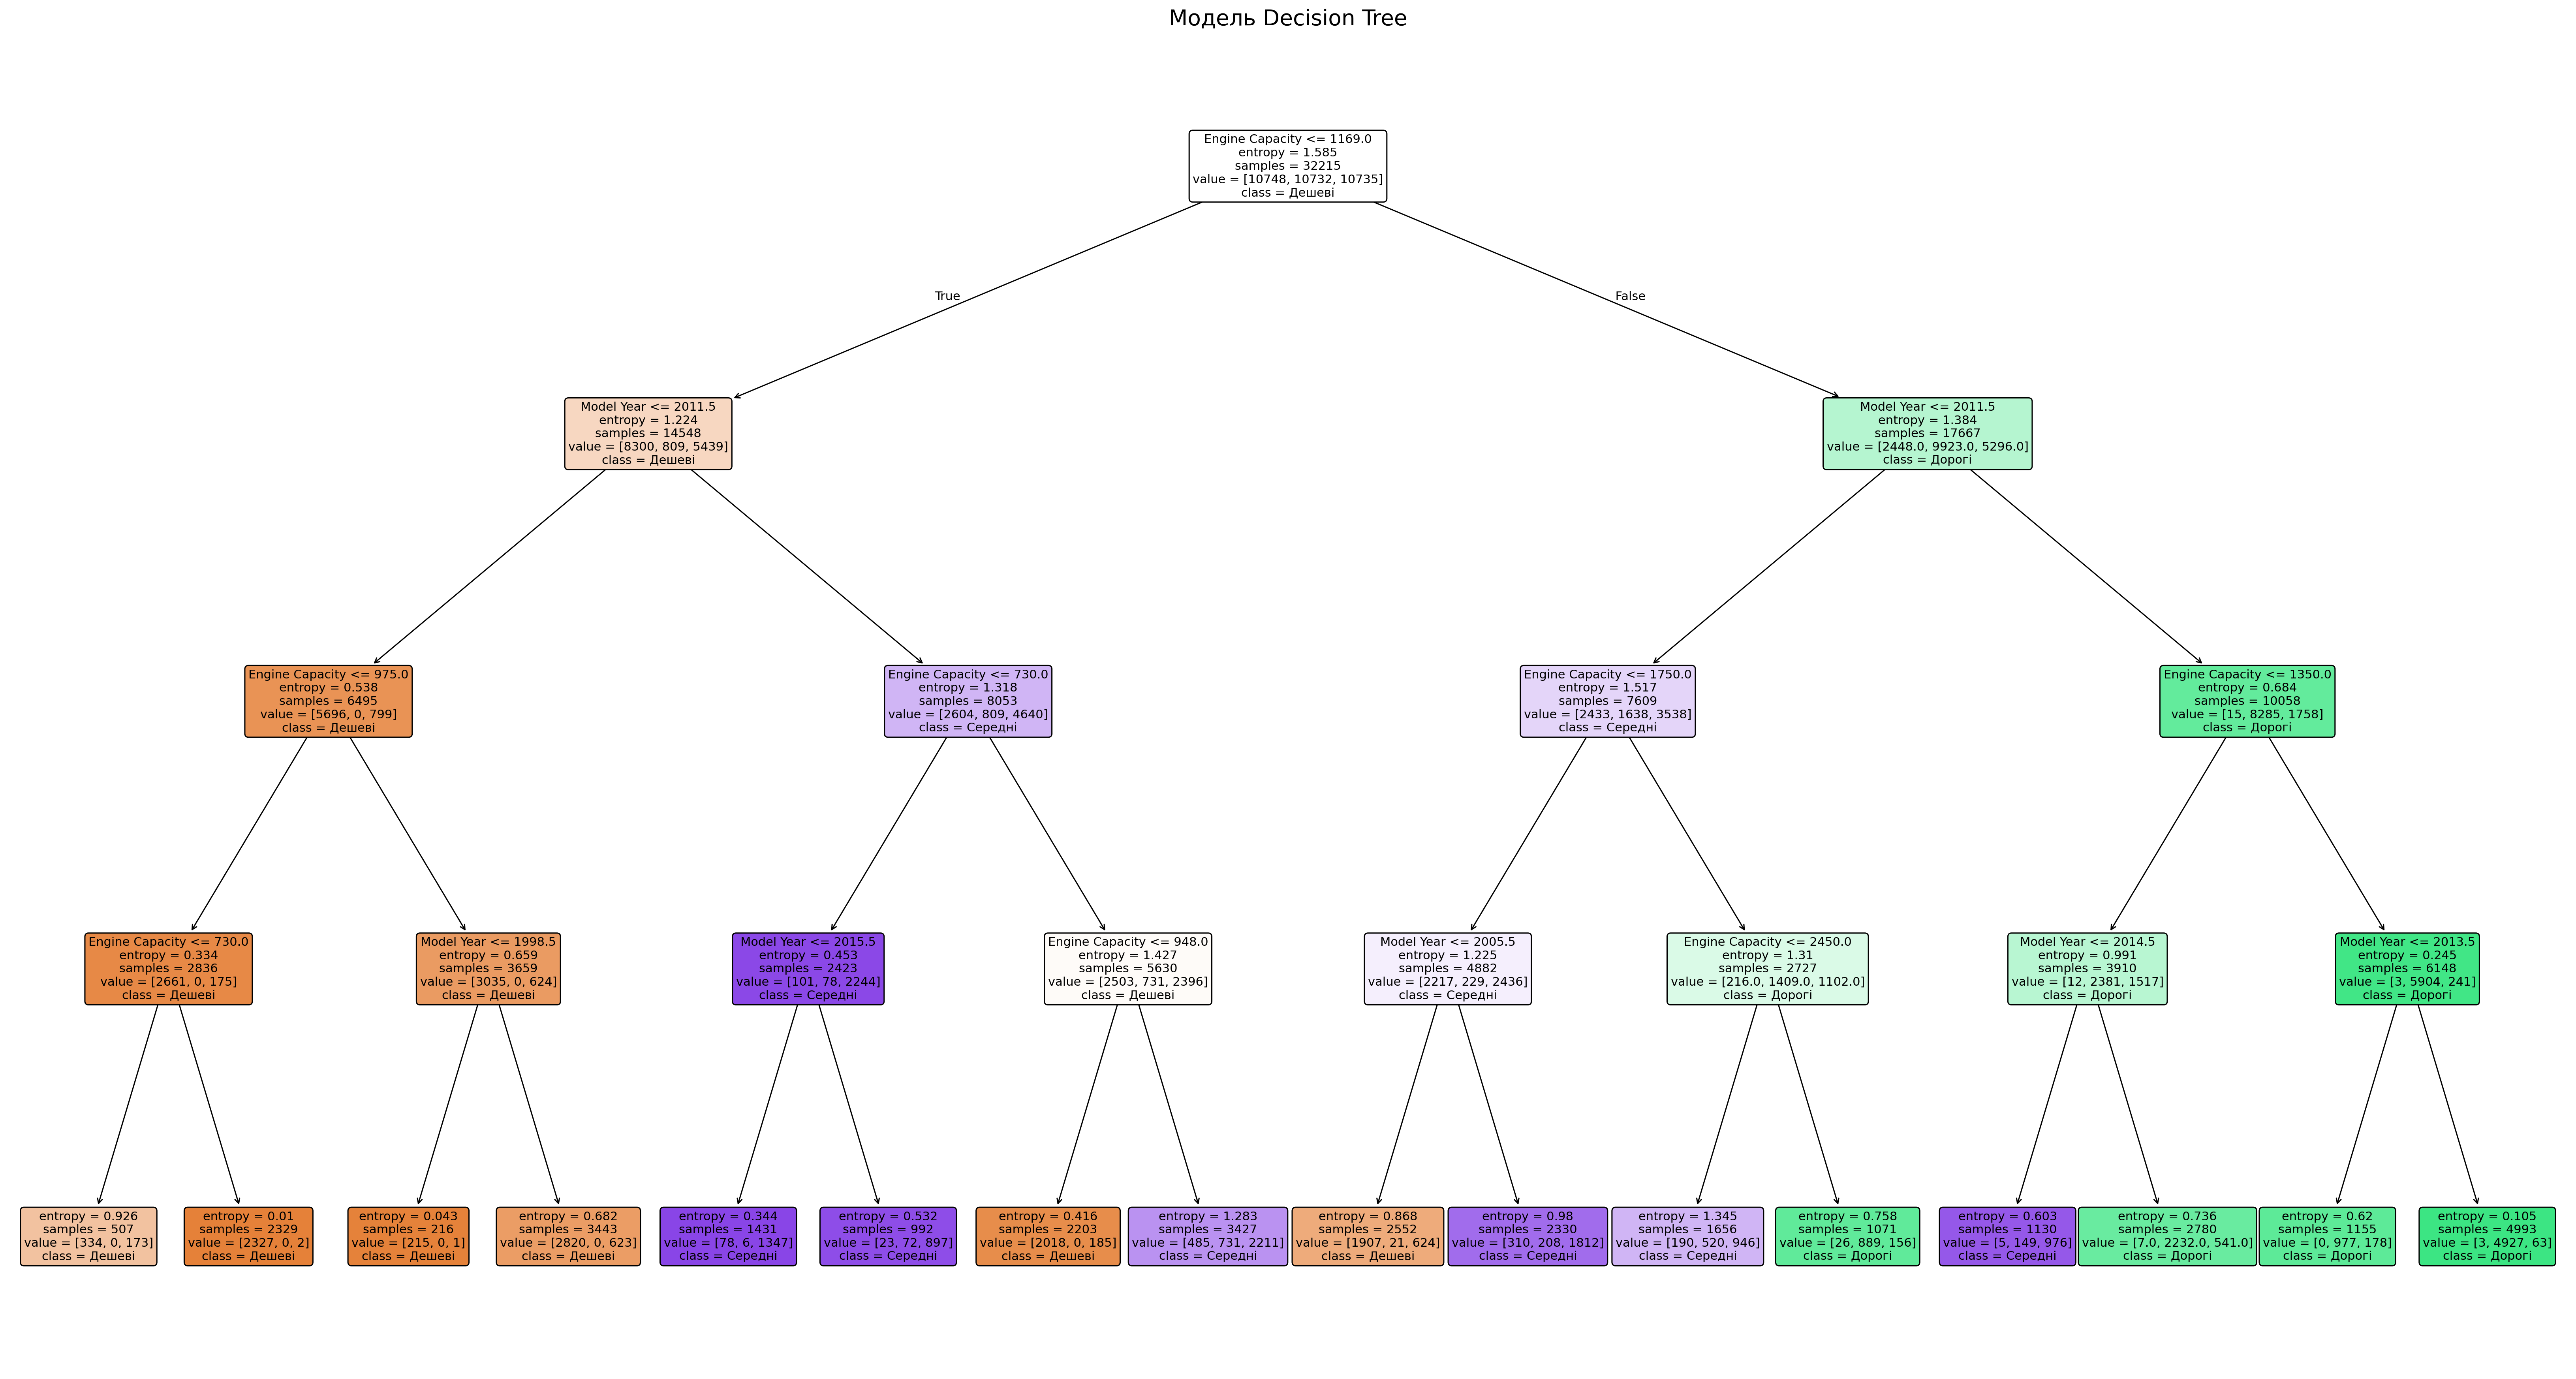


Точність Decision Tree: 0.833

Докладний звіт по класах:
              precision    recall  f1-score   support

      Дешеві       0.86      0.89      0.88      4606
      Дорогі       0.90      0.84      0.87      4600
     Середні       0.75      0.77      0.76      4601

    accuracy                           0.83     13807
   macro avg       0.84      0.83      0.83     13807
weighted avg       0.84      0.83      0.83     13807



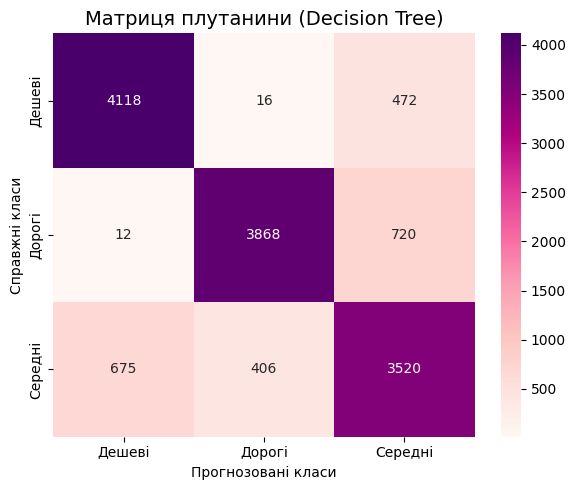

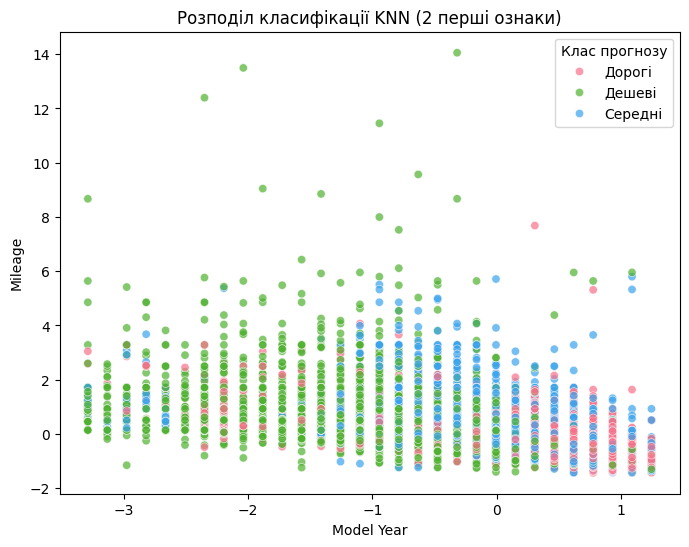


Точність KNN: 0.829

Докладний звіт по класах:
              precision    recall  f1-score   support

      Дешеві       0.86      0.88      0.87      4606
      Дорогі       0.87      0.87      0.87      4600
     Середні       0.76      0.73      0.74      4601

    accuracy                           0.83     13807
   macro avg       0.83      0.83      0.83     13807
weighted avg       0.83      0.83      0.83     13807



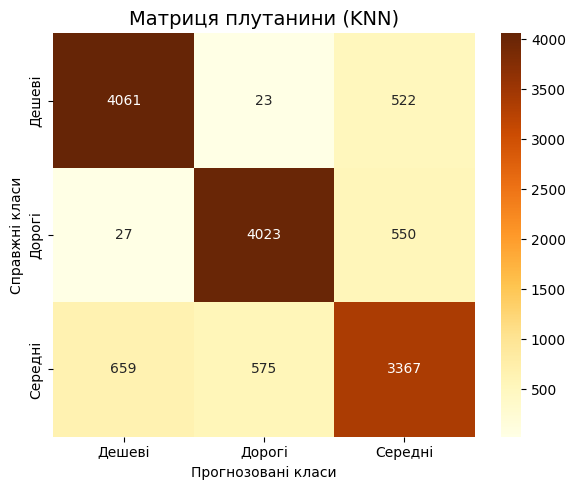


Порівняння точності моделей:
Decision Tree Accuracy: 0.833
KNN Accuracy:          0.829

--- ВИСНОВКИ ---
1) Модель Decision Tree показала вищу точність (0.833) порівняно з KNN (0.829).
2) Дерева рішень краще інтерпретуються — видно вплив кожної ознаки на клас.
3) Метод KNN простіший, але чутливий до масштабування та кількості сусідів.
4) Для задачі класифікації автомобілів за ціновими категоріями обидва методи дали адекватні результати.


In [1]:
# -*- coding: utf-8 -*-
"""Lab3.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1aK8DvvRcKIOGsh-5PbkVdAOipD7OuwB4
"""

!pip install -q scikit-learn matplotlib pandas numpy graphviz

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

# --- 1. Завантаження даних ---
DATA_PATH = 'Clean Data_pakwheels.csv'
df = pd.read_csv(DATA_PATH)

# --- 2. Підготовка даних ---
price_col = 'Price' if 'Price' in df.columns else [c for c in df.columns if 'price' in c.lower()][0]
df['price_class'] = pd.qcut(df[price_col], q=3, labels=['Дешеві', 'Середні', 'Дорогі'])

selected_features = ['Model Year', 'Mileage', 'Engine Capacity']
X = df[selected_features].copy()
y = df['price_class']

# Заповнення пропусків
X.fillna(X.median(), inplace=True)

# Кодування цільової змінної
le = LabelEncoder()
y_enc = le.fit_transform(y)

# Розділення на тренувальну і тестову вибірку
X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.3, random_state=42, stratify=y_enc)

# --- 3. Модель 1: Decision Tree ---
tree_clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
tree_clf.fit(X_train, y_train)
y_pred_tree = tree_clf.predict(X_test)

# --- 4. Візуалізація Decision Tree ---
plt.figure(figsize=(38, 20), dpi=220)
plot_tree(tree_clf, feature_names=selected_features, class_names=le.classes_, filled=True, rounded=True, fontsize=10)
plt.title("Модель Decision Tree", fontsize=18)
plt.savefig("decision_tree.png", bbox_inches='tight') # зберігає чітко в PNG
plt.show()

# --- 5. Показники якості Decision Tree ---
acc_tree = accuracy_score(y_test, y_pred_tree)
print(f"\nТочність Decision Tree: {acc_tree:.3f}")
print("\nДокладний звіт по класах:")
print(classification_report(y_test, y_pred_tree, target_names=le.classes_))

# Матриця плутанини для Decision Tree
cm_tree = confusion_matrix(y_test, y_pred_tree)
plt.figure(figsize=(6,5))
sns.heatmap(cm_tree, annot=True, fmt='d',
            cmap="RdPu",   # рожево-малинова гама
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title("Матриця плутанини (Decision Tree)", fontsize=14)
plt.xlabel("Прогнозовані класи")
plt.ylabel("Справжні класи")
plt.tight_layout()
plt.show()


# --- 6. Модель 2: KNN ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_scaled, y_enc, test_size=0.3, random_state=42, stratify=y_enc)

knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_s, y_train_s)
y_pred_knn = knn_clf.predict(X_test_s)

# --- 7. Візуалізація KNN ---
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_test_s[:,0], y=X_test_s[:,1], hue=le.inverse_transform(y_pred_knn), palette="husl", alpha=0.7)
plt.title("Розподіл класифікації KNN (2 перші ознаки)")
plt.xlabel(selected_features[0])
plt.ylabel(selected_features[1])
plt.legend(title="Клас прогнозу")
plt.show()

# --- 8. Показники якості KNN ---
acc_knn = accuracy_score(y_test_s, y_pred_knn)
print(f"\nТочність KNN: {acc_knn:.3f}")
print("\nДокладний звіт по класах:")
print(classification_report(y_test_s, y_pred_knn, target_names=le.classes_))

# Матриця плутанини для KNN
cm_knn = confusion_matrix(y_test_s, y_pred_knn)
plt.figure(figsize=(6,5))
sns.heatmap(cm_knn, annot=True, fmt='d',
            cmap="YlOrBr",  # жовто-коричнева гама (тепла)
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title("Матриця плутанини (KNN)", fontsize=14)
plt.xlabel("Прогнозовані класи")
plt.ylabel("Справжні класи")
plt.tight_layout()
plt.show()

# --- 9. Порівняння моделей ---
print("\nПорівняння точності моделей:")
print(f"Decision Tree Accuracy: {acc_tree:.3f}")
print(f"KNN Accuracy:          {acc_knn:.3f}")

# --- 10. Висновки ---
print("\n--- ВИСНОВКИ ---")
if acc_tree > acc_knn:
    print(f"1) Модель Decision Tree показала вищу точність ({acc_tree:.3f}) порівняно з KNN ({acc_knn:.3f}).")
else:
    print(f"1) Модель KNN показала вищу точність ({acc_knn:.3f}) порівняно з Decision Tree ({acc_tree:.3f}).")

print("2) Дерева рішень краще інтерпретуються — видно вплив кожної ознаки на клас.")
print("3) Метод KNN простіший, але чутливий до масштабування та кількості сусідів.")
print("4) Для задачі класифікації автомобілів за ціновими категоріями обидва методи дали адекватні результати.")